# Leicester's players vs the league's top 10

Every claim like "Mahrez completed the most dribbles" or "Vardy was 2nd for goals" is shown here with the players he was competing against.
Each panel shows the Premier League's top 10 for one 2015/16 season total. Leicester players are blue.
If no Leicester player made the top 10, the best Leicester player is added below a dashed line with his rank.

**Source:** StatsBomb Open Data (all 380 matches).
StatsBomb's counts can differ slightly from official Opta figures; for example, StatsBomb gives Mahrez 10 assists, the official count is 11.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()  # project folder
REPO = next(p for p in [ROOT, *ROOT.parents] if (p / "src" / "football_analytics").exists())  # repo root: shared code and downloaded data
DATA = REPO / "data" / "processed" / "2_27"
FIGS = ROOT / "reports" / "figures"
LEI = "Leicester City"
BLUE, GREY, DARK, MUTED = "#1F5FAD", "#C9C7BF", "#3D3D3A", "#6B6A64"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": GREY, "axes.labelcolor": DARK, "xtick.color": DARK, "ytick.color": DARK,
})
ABBR = {"AFC Bournemouth": "BOU", "Arsenal": "ARS", "Aston Villa": "AVL", "Chelsea": "CHE", "Crystal Palace": "CRY",
        "Everton": "EVE", "Leicester City": "LEI", "Liverpool": "LIV", "Manchester City": "MCI", "Manchester United": "MUN",
        "Newcastle United": "NEW", "Norwich City": "NOR", "Southampton": "SOU", "Stoke City": "STK", "Sunderland": "SUN",
        "Swansea City": "SWA", "Tottenham Hotspur": "TOT", "Watford": "WAT", "West Bromwich Albion": "WBA", "West Ham United": "WHU"}

e = pd.read_parquet(DATA / "events.parquet")
players = pd.read_parquet(DATA / "player_season.parquet").set_index("player_id")

In [2]:
shots = e[e.type == "Shot"].assign(xg=lambda d: d.shot_statsbomb_xg.astype(float), goal=lambda d: d.shot_outcome == "Goal")
np_shots = shots[shots.shot_type != "Penalty"]
f = lambda mask: e[mask].groupby("player_id").size()
tackle = (e.type == "Duel") & (e.duel_type == "Tackle")
assist = e.pass_goal_assist.fillna(False).astype(bool)
key_pass = e.pass_shot_assist.fillna(False).astype(bool) | assist

S = players.join(pd.DataFrame({
    "Goals": shots.groupby("player_id").goal.sum(),
    "Non-penalty goals": np_shots.groupby("player_id").goal.sum(),
    "xG": shots.groupby("player_id").xg.sum(),
    "np_xg": np_shots.groupby("player_id").xg.sum(),
    "Assists": f(assist),
    "Chances created": f(key_pass),
    "Completed dribbles": f((e.type == "Dribble") & (e.dribble_outcome == "Complete")),
    "Fouls won": f(e.type == "Foul Won"),
    "Counter-attack goals": shots[(shots.play_pattern == "From Counter") & shots.goal].groupby("player_id").size(),
    "Tackles": f(tackle),
    "Interceptions": f(e.type == "Interception"),
    "Ball recoveries": f(e.type == "Ball Recovery"),
    "Blocks": f(e.type == "Block"),
    "Clearances": f(e.type == "Clearance"),
    "Pressures": f(e.type == "Pressure"),
    "Pressures in attacking third": f((e.type == "Pressure") & (e.start_x >= 80)),
})).fillna(0)
S["Goals + assists"] = S["Goals"] + S["Assists"]
S["Tackles + interceptions"] = S["Tackles"] + S["Interceptions"]
S["Non-penalty goals minus xG"] = (S["Non-penalty goals"] - S["np_xg"]).round(1)
S = S[S.position_group != "Goalkeeper"]
S["label"] = S.display_name + " (" + S.main_team.map(ABBR) + ")"

In [3]:
def leaderboard(ax, col, n=10, fmt="{:.0f}", title=None):
    s = S.sort_values(col, ascending=False)
    rank = s[col].rank(ascending=False, method="min").astype(int)
    top = s.head(n)
    rows = list(top.index)
    extra = None
    if not (top.main_team == LEI).any():
        best = s[s.main_team == LEI].index[0]
        extra = best
        rows.append(best)
    y = np.arange(len(rows))[::-1].astype(float)
    if extra is not None:
        y[-1] -= 0.6
    vals = s.loc[rows, col].values
    colors = [BLUE if S.loc[i, "main_team"] == LEI else GREY for i in rows]
    ax.barh(y, vals, color=colors, height=0.72)
    vmax = s[col].iloc[0]
    for yi, v, i in zip(y, vals, rows):
        lei = S.loc[i, "main_team"] == LEI
        ax.text(v + vmax * 0.015, yi, fmt.format(v), va="center", fontsize=8.5,
                color=BLUE if lei else DARK, fontweight="bold" if lei else "normal")
    labels = [f"{rank[i]}. {S.loc[i, 'label']}" for i in rows]
    ax.set_yticks(y, labels, fontsize=8.5)
    for t, i in zip(ax.get_yticklabels(), rows):
        if S.loc[i, "main_team"] == LEI:
            t.set_color(BLUE); t.set_fontweight("bold")
    if extra is not None:
        ax.axhline(y[-1] + 0.8, color=GREY, lw=0.8, ls="--")
    ax.set_xlim(0, vmax * 1.18)
    ax.set_xticks([])
    ax.tick_params(axis="y", length=0)
    ax.set_title(title or col, loc="left", fontsize=11, fontweight="bold", pad=6)

def grid(cols, name, suptitle, sub, ncols=3, fmts=None):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 3.9 * nrows))
    for ax, c in zip(axes.flat, cols):
        leaderboard(ax, c, fmt=(fmts or {}).get(c, "{:.0f}"))
    for ax in list(axes.flat)[len(cols):]:
        ax.axis("off")
    fig.suptitle(suptitle, x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.085)
    fig.text(0.01, 1.02, sub, fontsize=10, color=MUTED)
    fig.tight_layout(rect=(0, 0, 1, 0.98), h_pad=2.2, w_pad=2.5)
    fig.text(0.01, -0.01, "Source: StatsBomb Open Data, Premier League 2015/16, season totals, outfield players. "
             "Rank shown before each name; ties share a rank", fontsize=8, color="#8A8880")
    fig.savefig(FIGS / name); plt.show()

## 1. Scoring and creating

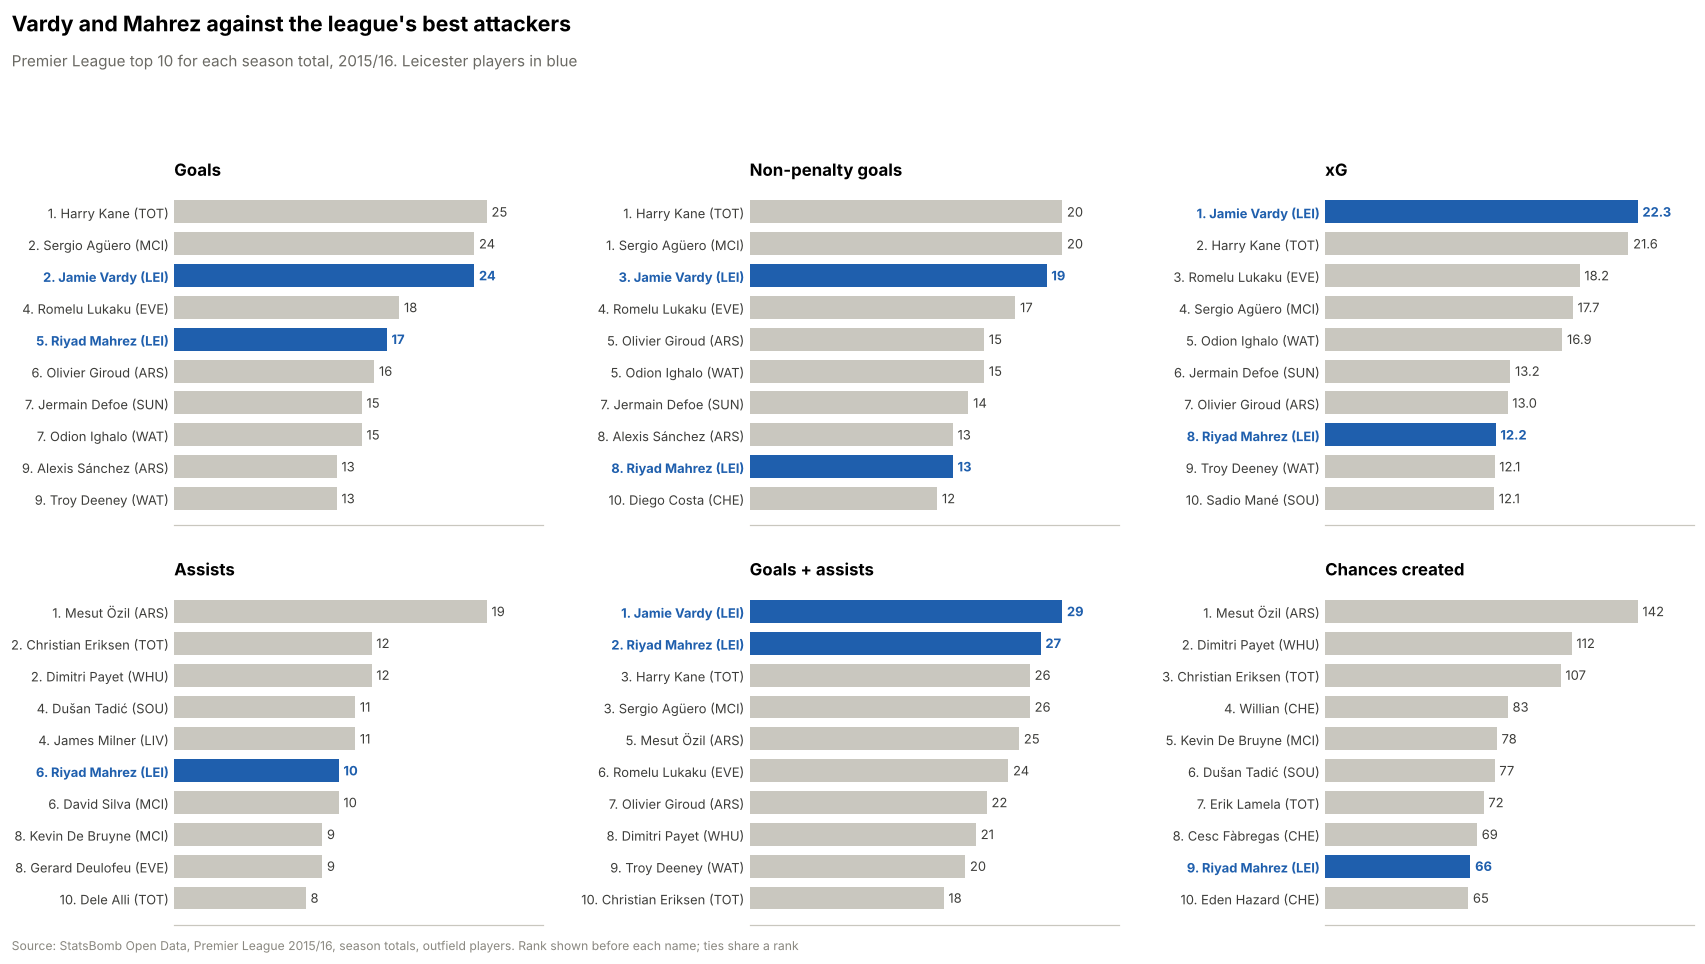

In [4]:
grid(["Goals", "Non-penalty goals", "xG", "Assists", "Goals + assists", "Chances created"],
     "20_leaderboards_attack.png", "Vardy and Mahrez against the league's best attackers",
     "Premier League top 10 for each season total, 2015/16. Leicester players in blue", fmts={"xG": "{:.1f}"})

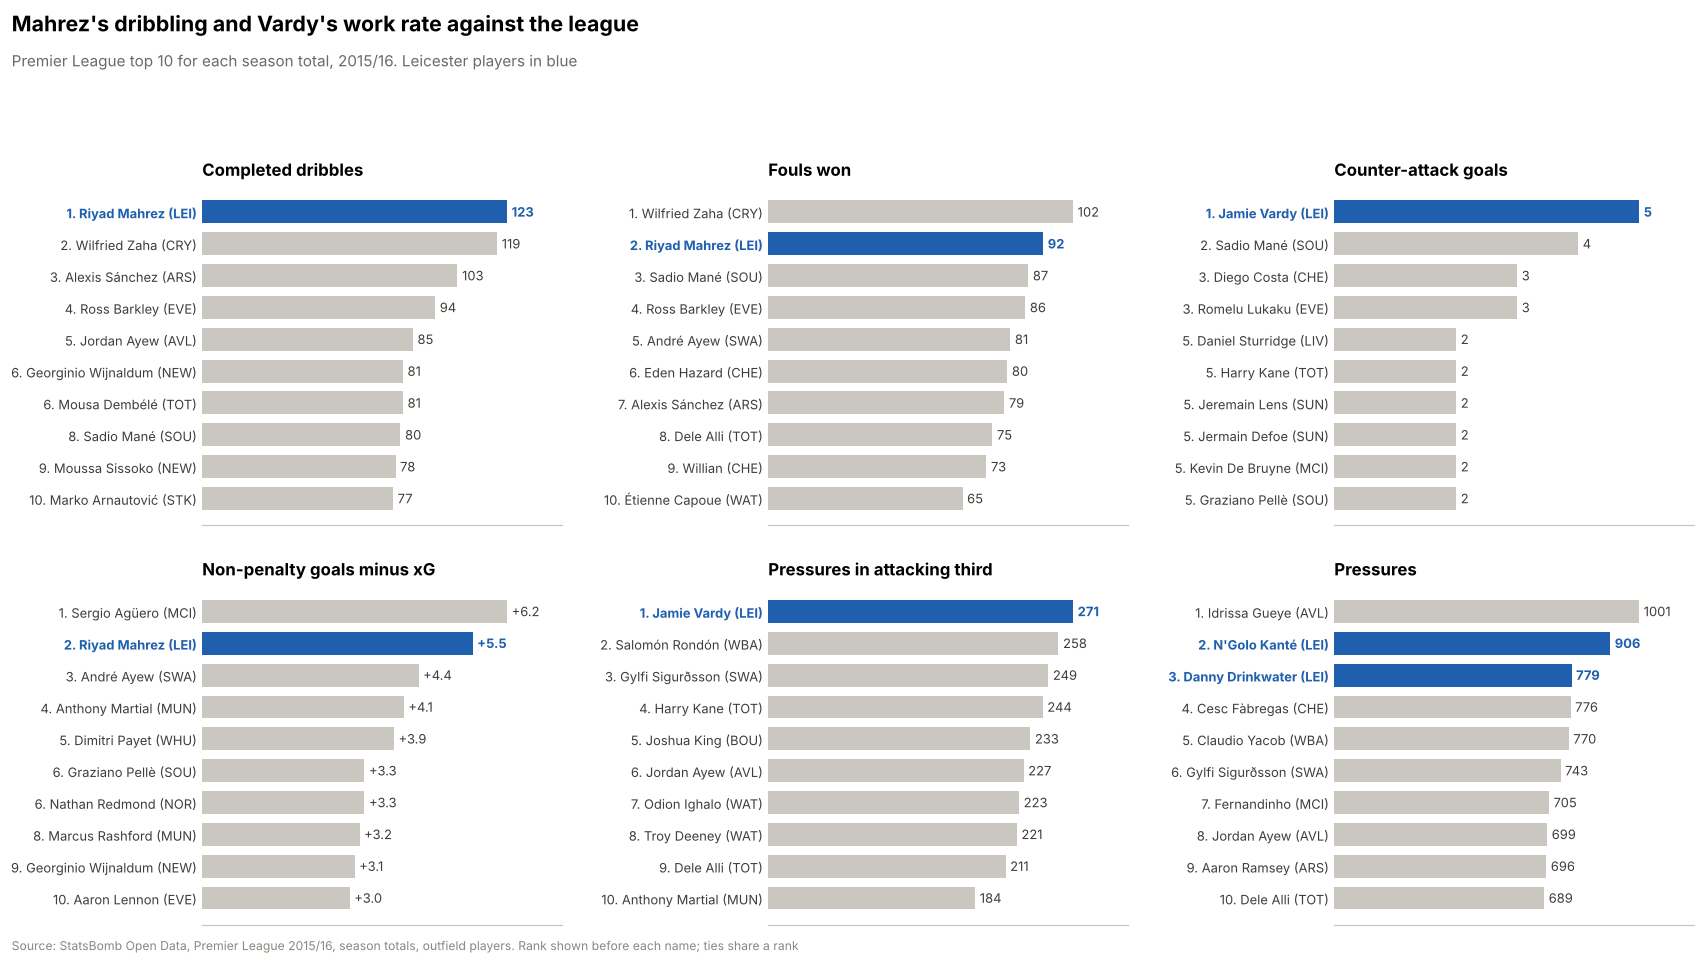

In [5]:
grid(["Completed dribbles", "Fouls won", "Counter-attack goals", "Non-penalty goals minus xG", "Pressures in attacking third", "Pressures"],
     "21_leaderboards_dribbling_pressing.png", "Mahrez's dribbling and Vardy's work rate against the league",
     "Premier League top 10 for each season total, 2015/16. Leicester players in blue",
     fmts={"Non-penalty goals minus xG": "{:+.1f}"})

## 2. Winning the ball and defending

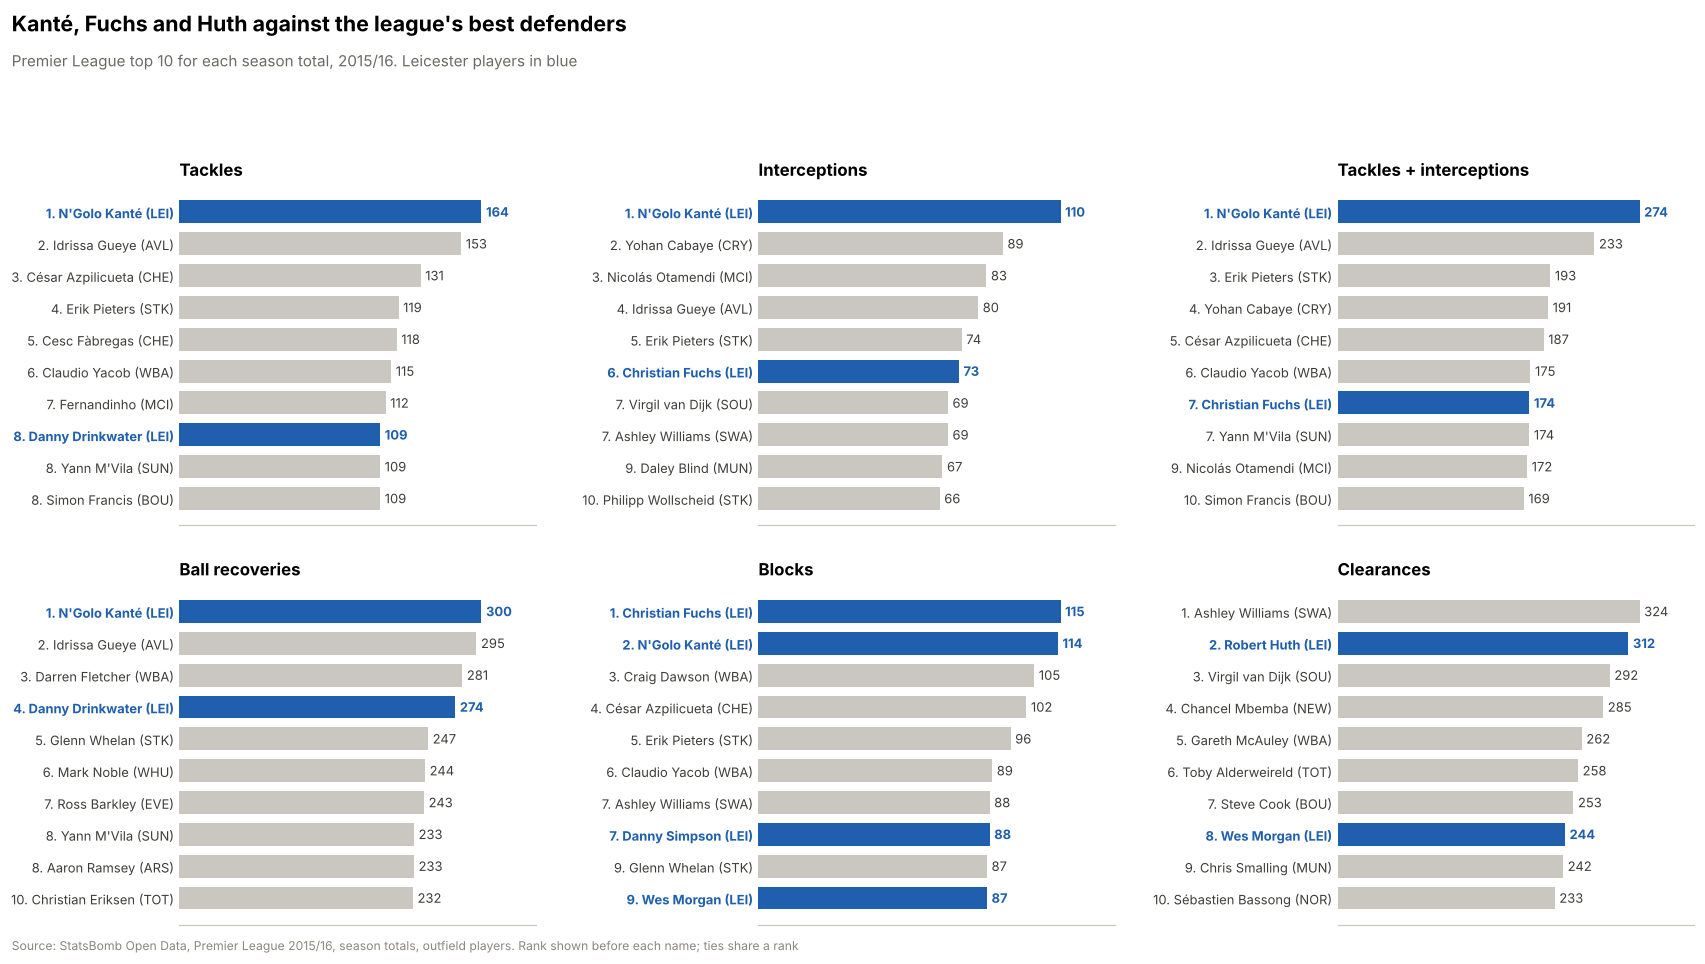

In [6]:
grid(["Tackles", "Interceptions", "Tackles + interceptions", "Ball recoveries", "Blocks", "Clearances"],
     "22_leaderboards_defending.png", "Kanté, Fuchs and Huth against the league's best defenders",
     "Premier League top 10 for each season total, 2015/16. Leicester players in blue")

## 3. Rank table: where each Leicester regular finished

Season-total rank among all 534 outfield players (1 = most).

In [7]:
cols = ["Goals", "Assists", "xG", "Chances created", "Completed dribbles", "Fouls won", "Tackles", "Interceptions",
        "Ball recoveries", "Blocks", "Clearances", "Pressures", "Pressures in attacking third"]
R = S[cols].rank(ascending=False, method="min").astype(int)
lei = S[(S.main_team == LEI) & (S.minutes >= 900)].sort_values("minutes", ascending=False)
R.loc[lei.index].set_index(lei.display_name)

,Goals,Assists,xG,Chances created,Completed dribbles,Fouls won,Tackles,Interceptions,Ball recoveries,Blocks,Clearances,Pressures,Pressures in attacking third
display_name,,,,,,,,,,,,,
Wes Morgan,122,249,96,325,248,208,95,41,168,9,8,177,287
Robert Huth,97,249,112,386,325,189,167,41,193,60,2,192,431
Jamie Vardy,2,29,1,44,60,84,140,281,162,128,310,65,1
N'Golo Kanté,178,56,264,89,35,101,1,1,1,2,96,2,62
Danny Drinkwater,122,13,169,44,97,114,8,76,4,23,102,3,57
Riyad Mahrez,5,6,8,9,1,2,100,92,20,12,204,36,21
Christian Fuchs,265,39,234,32,222,258,14,6,106,1,38,64,156
Marc Albrighton,122,13,125,11,19,91,57,156,38,19,173,25,40
Danny Simpson,265,249,254,266,234,247,109,17,125,7,42,129,199
